In [41]:
%load_ext cuml.accel

The cuml.accel extension is already loaded. To reload it, use:
  %reload_ext cuml.accel


In [ ]:
%pip install kagglehub

In [43]:
import pandas as pd
import seaborn as sns
import kagglehub
import glob

path = kagglehub.dataset_download("mrdaniilak/russia-real-estate-20182021")
files = glob.glob(path + "/**/*.csv", recursive=True)
df = pd.read_csv(files[0])
print(df.columns)

Using Colab cache for faster access to the 'russia-real-estate-20182021' dataset.
Index(['price', 'date', 'time', 'geo_lat', 'geo_lon', 'region',
       'building_type', 'level', 'levels', 'rooms', 'area', 'kitchen_area',
       'object_type'],
      dtype='object')


In [44]:
region_name = {
    '2661': 'Санкт-Петербург',
    '3446': 'Ленинградская область',
    '3': 'Москва',
    '81': 'Московская область',
    '2843': 'Краснодарский край',
    '2871': 'Нижегородская область',
    '3230': 'Ростовская область',
    '3106': 'Самарская область',
    '2922': 'Республика Татарстан',
    '2900': 'Ставропольский край',
    '2722': 'Республика Башкортостан',
    '6171': 'Свердловская область',
    '4417': 'Республика Коми',
    '5282': 'Челябинская область',
    '5368': 'Иркутская область',
    '5520': 'Пермский край',
    '6817': 'Алтайский край',
    '9579': 'Республика Бурятия',
    '2604': 'Ярославская область',
    '1010': 'Удмуртская Республика',
    '7793': 'Псковская область',
    '13919': 'Республика Северная Осетия — Алания',
    '2860': 'Кемеровская область',
    '3019': 'Чувашская Республика',
    '4982': 'Республика Марий Эл',
    '9648': 'Кабардино-Балкарская Республика',
    '5241': 'Республика Мордовия',
    '3870': 'Красноярский край',
    '3991': 'Тюменская область',
    '2359': 'Республика Хакасия',
    '9654': 'Новосибирская область',
    '2072': 'Воронежская область',
    '8090': 'Республика Карелия',
    '4007': 'Республика Дагестан',
    '11171': 'Республика Саха (Якутия)',
    '10160': 'Забайкальский край',
    '7873': 'Республика Крым',
    '6937': 'Республика Крым',
    '2594': 'Кировская область',
    '8509': 'Республика Калмыкия',
    '11416': 'Республика Адыгея',
    '11991': 'Карачаево-Черкесская Республика',
    '5178': 'Республика Тыва',
    '13913': 'Республика Ингушетия',
    '6309': 'Республика Алтай',
    '5952': 'Белгородская область',
    '6543': 'Архангельская область',
    '2880': 'Тверская область',
    '5993': 'Пензенская область',
    '2484': 'Ханты-Мансийский автономный округ',
    '4240': 'Липецкая область',
    '5789': 'Владимирская область',
    '14880': 'Ямало-Ненецкий автономный округ',
    '1491': 'Рязанская область',
    '2885': 'Чеченская Республика',
    '5794': 'Смоленская область',
    '2528': 'Саратовская область',
    '4374': 'Вологодская область',
    '4695': 'Волгоградская область',
    '2328': 'Калужская область',
    '5143': 'Тульская область',
    '2806': 'Тамбовская область',
    '14368': 'Мурманская область',
    '5736': 'Новгородская область',
    '7121': 'Курская область',
    '4086': 'Хабаровский край',
    '821': 'Брянская область',
    '10582': 'Астраханская область',
    '7896': 'Калининградская область',
    '8640': 'Омская область',
    '5703': 'Курганская область',
    '10201': 'Томская область',
    '4249': 'Ульяновская область',
    '3153': 'Оренбургская область',
    '4189': 'Костромская область',
    '2814': 'Орловская область',
    '13098': 'Камчатский край',
    '8894': 'Ивановская область',
    '7929': 'Амурская область',
    '16705': 'Магаданская область',
    '69': 'Еврейская автономная область',
    '4963': 'Приморский край',
    '1901': 'Сахалинская область',
    '61888': 'Ненецкий автономный округ'
}

In [45]:
df

,price,date,time,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type
0,6050000,2018-02-19,20:00:21,59.805808,30.376141,2661,1,8,10,3,82.6,10.8,1
1,8650000,2018-02-27,12:04:54,55.683807,37.297405,81,3,5,24,2,69.1,12.0,1
2,4000000,2018-02-28,15:44:00,56.295250,44.061637,2871,1,5,9,3,66.0,10.0,1
3,1850000,2018-03-01,11:24:52,44.996132,39.074783,2843,4,12,16,2,38.0,5.0,11
4,5450000,2018-03-01,17:42:43,55.918767,37.984642,81,3,13,14,2,60.0,10.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5477001,19739760,2021-05-01,20:13:58,55.804736,37.750898,3,1,8,17,4,93.2,13.8,11
5477002,12503160,2021-05-01,20:14:01,55.841415,37.489624,3,2,17,32,2,45.9,6.6,11
5477003,8800000,2021-05-01,20:14:04,56.283909,44.075408,2871,2,4,17,3,86.5,11.8,1
5477004,11831910,2021-05-01,20:14:12,55.804736,37.750898,3,1,8,33,2,52.1,18.9,11


## Задача 1

In [46]:
TARGET = 'price'

region_name = {int(k): v for k, v in region_name.items()}

reg_names = df.groupby('region')[TARGET].count().reset_index(name='target_count')

reg_names['region_name'] = reg_names['region'].map(region_name)

reg_names.nlargest(10, 'target_count')


,region,target_count,region_name
70,9654,1049435,Новосибирская область
18,2843,637224,Краснодарский край
2,81,500368,Московская область
14,2661,461820,Санкт-Петербург
0,3,439511,Москва
54,6171,237289,Свердловская область
24,2922,230545,Республика Татарстан
28,3230,222652,Ростовская область
45,5282,155645,Челябинская область
31,3991,141633,Тюменская область


В качестве региона для построения модели была выбрана **Челябинская область**

In [47]:
SEL_REGION = 5282
df = df[df['region'] == SEL_REGION]

df = df.dropna(subset=[TARGET])

df

,price,date,time,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type
37,3160000,2018-04-11,15:58:47,55.172116,61.279772,5282,3,13,16,2,56.0,11.0,11
124,2050000,2018-07-26,07:38:12,55.107360,61.616595,5282,3,6,9,3,61.0,9.0,1
278,2050000,2018-09-08,00:29:10,55.166017,61.292384,5282,1,1,10,2,65.0,14.0,1
1491,1900000,2018-09-08,03:59:06,55.158606,61.446504,5282,1,7,10,1,43.0,9.0,11
1545,1950000,2018-09-08,05:50:03,55.123232,61.604227,5282,1,5,5,3,70.0,10.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5476777,2270000,2021-05-01,19:32:40,55.246425,61.370958,5282,4,3,5,4,74.4,8.6,1
5476851,2400000,2021-05-01,19:46:25,55.128211,61.420405,5282,4,4,5,3,60.0,6.0,1
5476861,1750000,2021-05-01,19:46:47,55.247058,61.371008,5282,3,2,3,2,46.7,10.0,1
5476862,3500000,2021-05-01,19:46:52,55.166973,61.290378,5282,1,9,10,2,61.0,8.0,1


### Удаление некорректных записей

In [48]:
df = df.drop_duplicates()

remove_cond = (
    (df['price'] <= 0) |
    (df['area'] <= 0) |
    (df['kitchen_area'] <= 0) |
    (df['kitchen_area'] >= df['area']) |
    (df['rooms'] < -1) | (df['rooms'] == 0) |
    (df['kitchen_area'] < 1) |
    (df['geo_lat'] == 0) | (df['geo_lon'] == 0) |
    (df['level'] < 1) |
    (df['levels'] < 1) |
    (df['level'] > df['levels'])
)

df = df[~remove_cond]
df

,price,date,time,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type
37,3160000,2018-04-11,15:58:47,55.172116,61.279772,5282,3,13,16,2,56.0,11.0,11
124,2050000,2018-07-26,07:38:12,55.107360,61.616595,5282,3,6,9,3,61.0,9.0,1
278,2050000,2018-09-08,00:29:10,55.166017,61.292384,5282,1,1,10,2,65.0,14.0,1
1491,1900000,2018-09-08,03:59:06,55.158606,61.446504,5282,1,7,10,1,43.0,9.0,11
1545,1950000,2018-09-08,05:50:03,55.123232,61.604227,5282,1,5,5,3,70.0,10.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5476777,2270000,2021-05-01,19:32:40,55.246425,61.370958,5282,4,3,5,4,74.4,8.6,1
5476851,2400000,2021-05-01,19:46:25,55.128211,61.420405,5282,4,4,5,3,60.0,6.0,1
5476861,1750000,2021-05-01,19:46:47,55.247058,61.371008,5282,3,2,3,2,46.7,10.0,1
5476862,3500000,2021-05-01,19:46:52,55.166973,61.290378,5282,1,9,10,2,61.0,8.0,1


Проверка на выбросы по признакам

In [49]:
display(
    df[['price', 'area', 'kitchen_area', 'level', 'levels', 'rooms', 'geo_lat', 'geo_lon', 'date', 'time']]
    .describe()
    .T[['min', '25%', '50%', '75%', 'max']]
    .round(2)
)

,min,25%,50%,75%,max
price,150.00,1355000.00,1780000.00,2350000.00,1.100000e+09
area,2.34,39.30,48.00,63.00,1.260000e+03
kitchen_area,1.00,7.00,9.00,10.60,2.100000e+02
level,1.00,2.00,4.00,7.00,2.600000e+01
levels,1.00,5.00,9.00,10.00,3.700000e+01
rooms,-1.00,1.00,2.00,2.00,9.000000e+00
geo_lat,52.39,55.13,55.17,55.19,5.629000e+01
geo_lon,57.15,61.29,61.36,61.42,6.299000e+01


Удаление выбросов по показателю цены на единицу площади

In [50]:

price_sqm = df['price'] / df['area']
lo_sqm, hi_sqm = price_sqm.quantile([0.005, 0.995])
df = df[price_sqm.between(lo_sqm, hi_sqm)]

display(
    df[['price', 'area', 'kitchen_area', 'level', 'levels', 'rooms', 'geo_lat', 'geo_lon', 'date', 'time']]
    .describe()
    .T[['min', '25%', '50%', '75%', 'max']]
    .round(2)
)

,min,25%,50%,75%,max
price,175000.00,1360000.00,1780000.00,2350000.00,28500000.00
area,10.00,39.10,48.00,63.00,500.00
kitchen_area,1.00,7.00,9.00,10.50,130.00
level,1.00,2.00,4.00,7.00,26.00
levels,1.00,5.00,9.00,10.00,37.00
rooms,-1.00,1.00,2.00,2.00,9.00
geo_lat,52.39,55.13,55.17,55.19,56.29
geo_lon,57.15,61.29,61.37,61.42,62.98


Явных выбросов в выборке не наблюдается с поправкой на то, что rooms=-1 представляется как квартира-студия

### Создание колонки с годом и удаление date и time

In [51]:

df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year

df = df.drop(columns=['date', 'time'])

/tmp/ipykernel_630/3772369790.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['date'] = pd.to_datetime(df['date'])
/tmp/ipykernel_630/3772369790.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['year'] = df['date'].dt.year


### Исключение 1% с каждого хвоста распределения по целевой переменной и по признакам с высокой скошенностью

In [52]:
def rem_q(d, col, q=0.01):
    lo, hi = d[col].quantile([q, 1 - q])
    return d[d[col].between(lo, hi)]

for col in ['price', 'area', 'kitchen_area']:
    df = rem_q(df, col)

### Исследование гистограмм и скошенности признаков

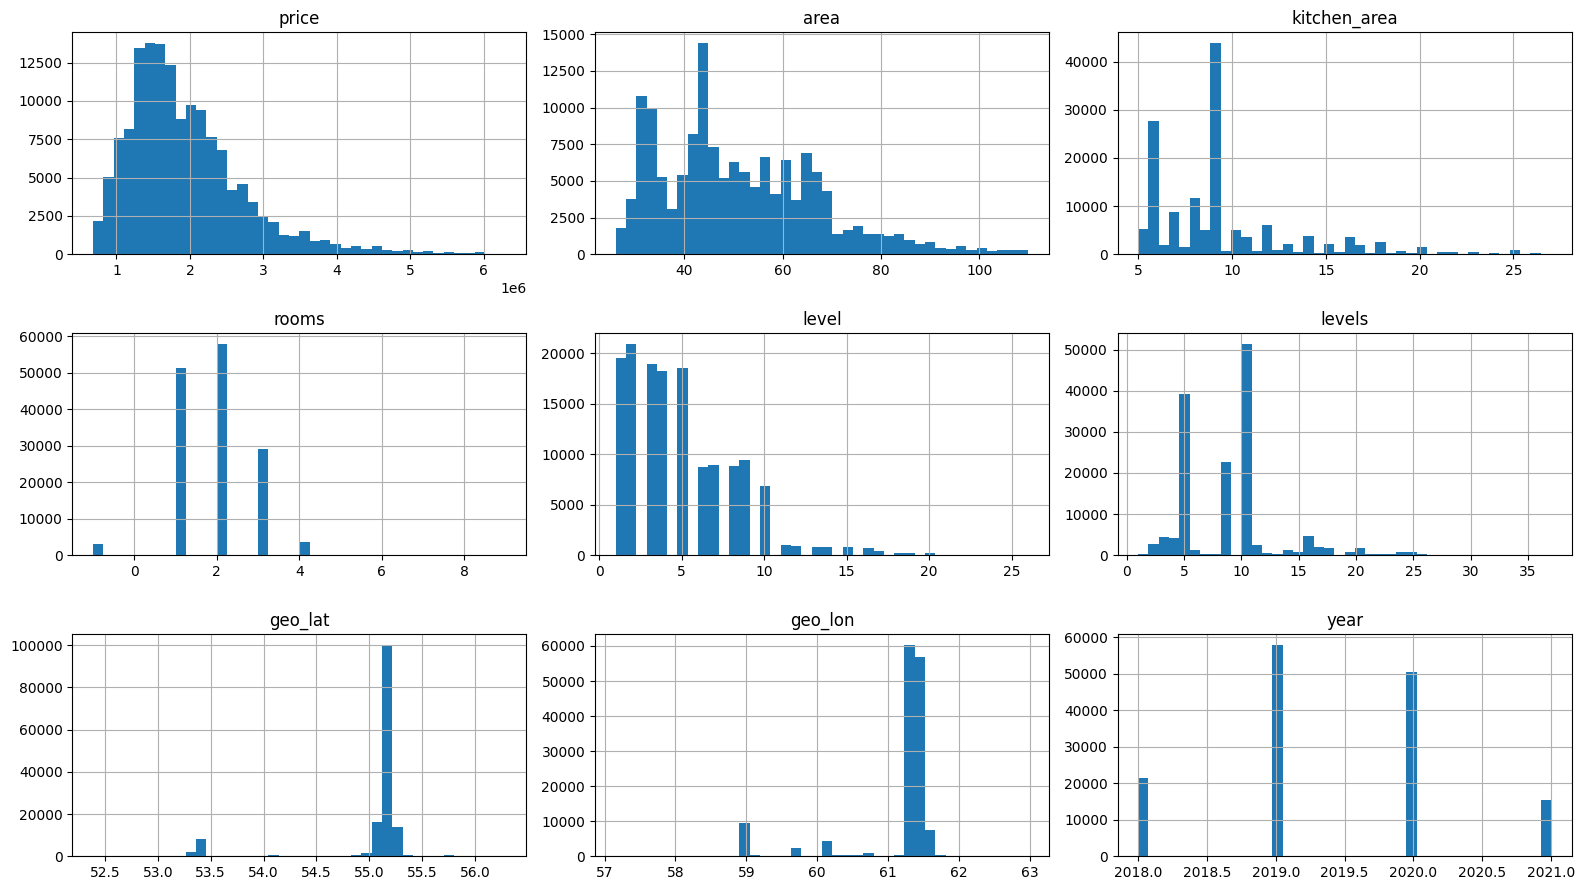

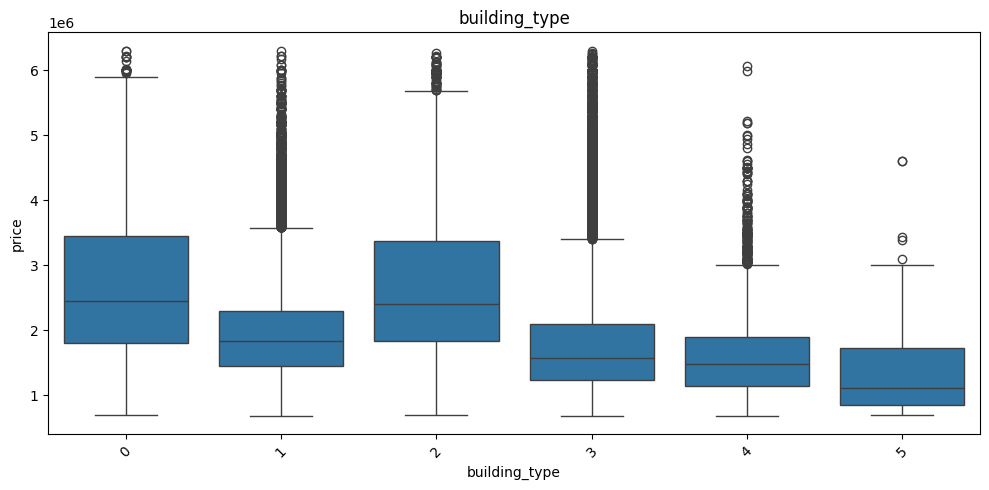

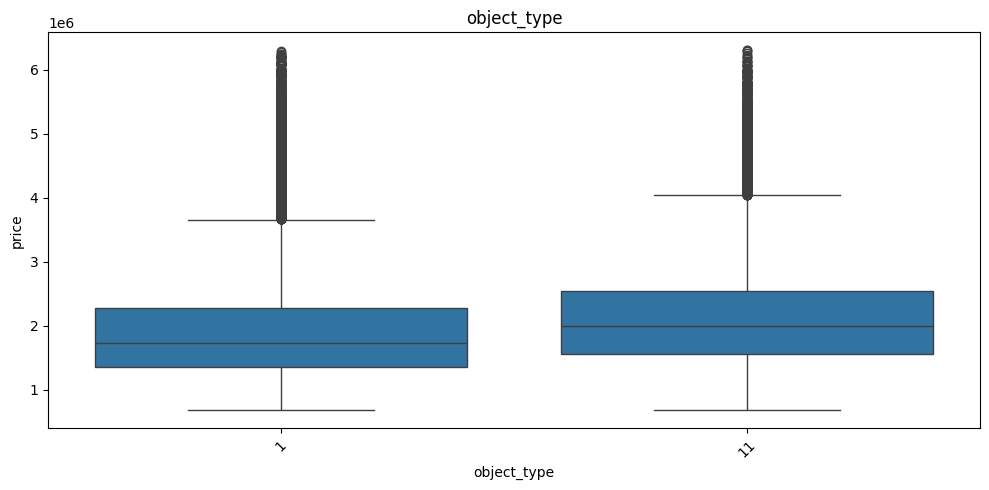

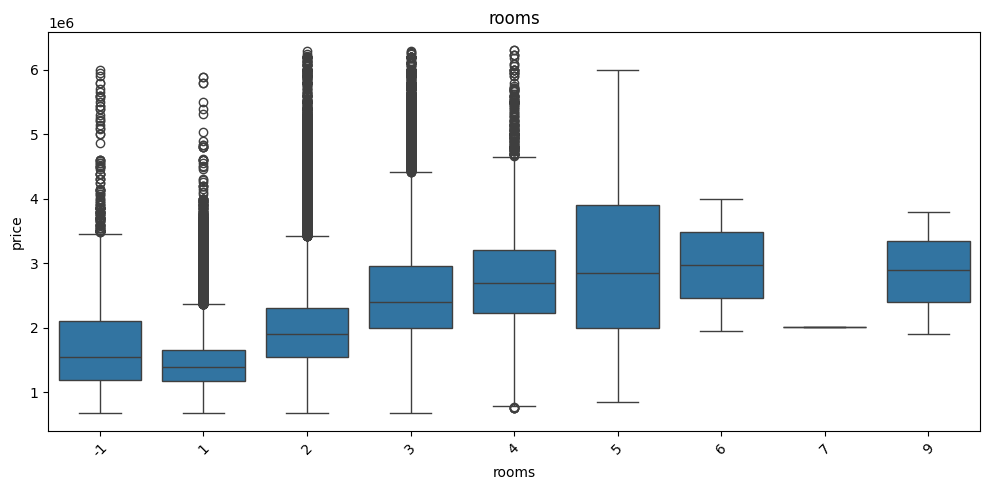

price           1.46
area            0.83
kitchen_area    1.69
rooms          -0.13
level           1.30
levels          1.21
geo_lat        -3.09
geo_lon        -2.50
year            0.08
dtype: float64


In [53]:
from matplotlib import pyplot as plt


num_features = ['price', 'area', 'kitchen_area', 'rooms', 'level', 'levels', 'geo_lat', 'geo_lon', 'year']
discr_feats = ['building_type', 'object_type', 'rooms']

df[num_features].hist(bins=40, figsize=(16, 9))
plt.tight_layout()
plt.show()


for cf in discr_feats:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df, x=cf, y='price')
    plt.title(f'{cf}')
    plt.xlabel(cf)
    plt.ylabel('price')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

print(df[num_features].skew().round(2))


Несмотря на то, что room является дискретным признаком, его можно определить в числовые, потому что он упорядочен и имеет корреляцию с таргетом

У признаков price и kitchen_area явно выражается сильная скошенность вправо. Эти признаки не являются категориальными, следовательно, можно попробовать их устранить нелинейным преобразованием, к примеру, логарифмированием

In [54]:
import numpy as np


for c in ['price', 'area', 'kitchen_area']:
    df['log_' + c] = np.log1p(df[c])
df['obj_type_11'] = (df['object_type'] == 11).astype(int)

print(df[['price', 'log_price', 'area', 'log_area', 'kitchen_area', 'log_kitchen_area']].skew().round(2))
df.head()

price               1.46
log_price           0.22
area                0.83
log_area            0.18
kitchen_area        1.69
log_kitchen_area    0.81
dtype: float64


,price,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type,year,log_price,log_area,log_kitchen_area,obj_type_11
37,3160000,55.172116,61.279772,5282,3,13,16,2,56.0,11.0,11,2018,14.966083,4.043051,2.484907,1
124,2050000,55.107360,61.616595,5282,3,6,9,3,61.0,9.0,1,2018,14.533351,4.127134,2.302585,0
278,2050000,55.166017,61.292384,5282,1,1,10,2,65.0,14.0,1,2018,14.533351,4.189655,2.708050,0
1491,1900000,55.158606,61.446504,5282,1,7,10,1,43.0,9.0,11,2018,14.457365,3.784190,2.302585,1
1545,1950000,55.123232,61.604227,5282,1,5,5,3,70.0,10.0,1,2018,14.483340,4.262680,2.397895,0


### Сравнение гистограмм после устранения скошенности

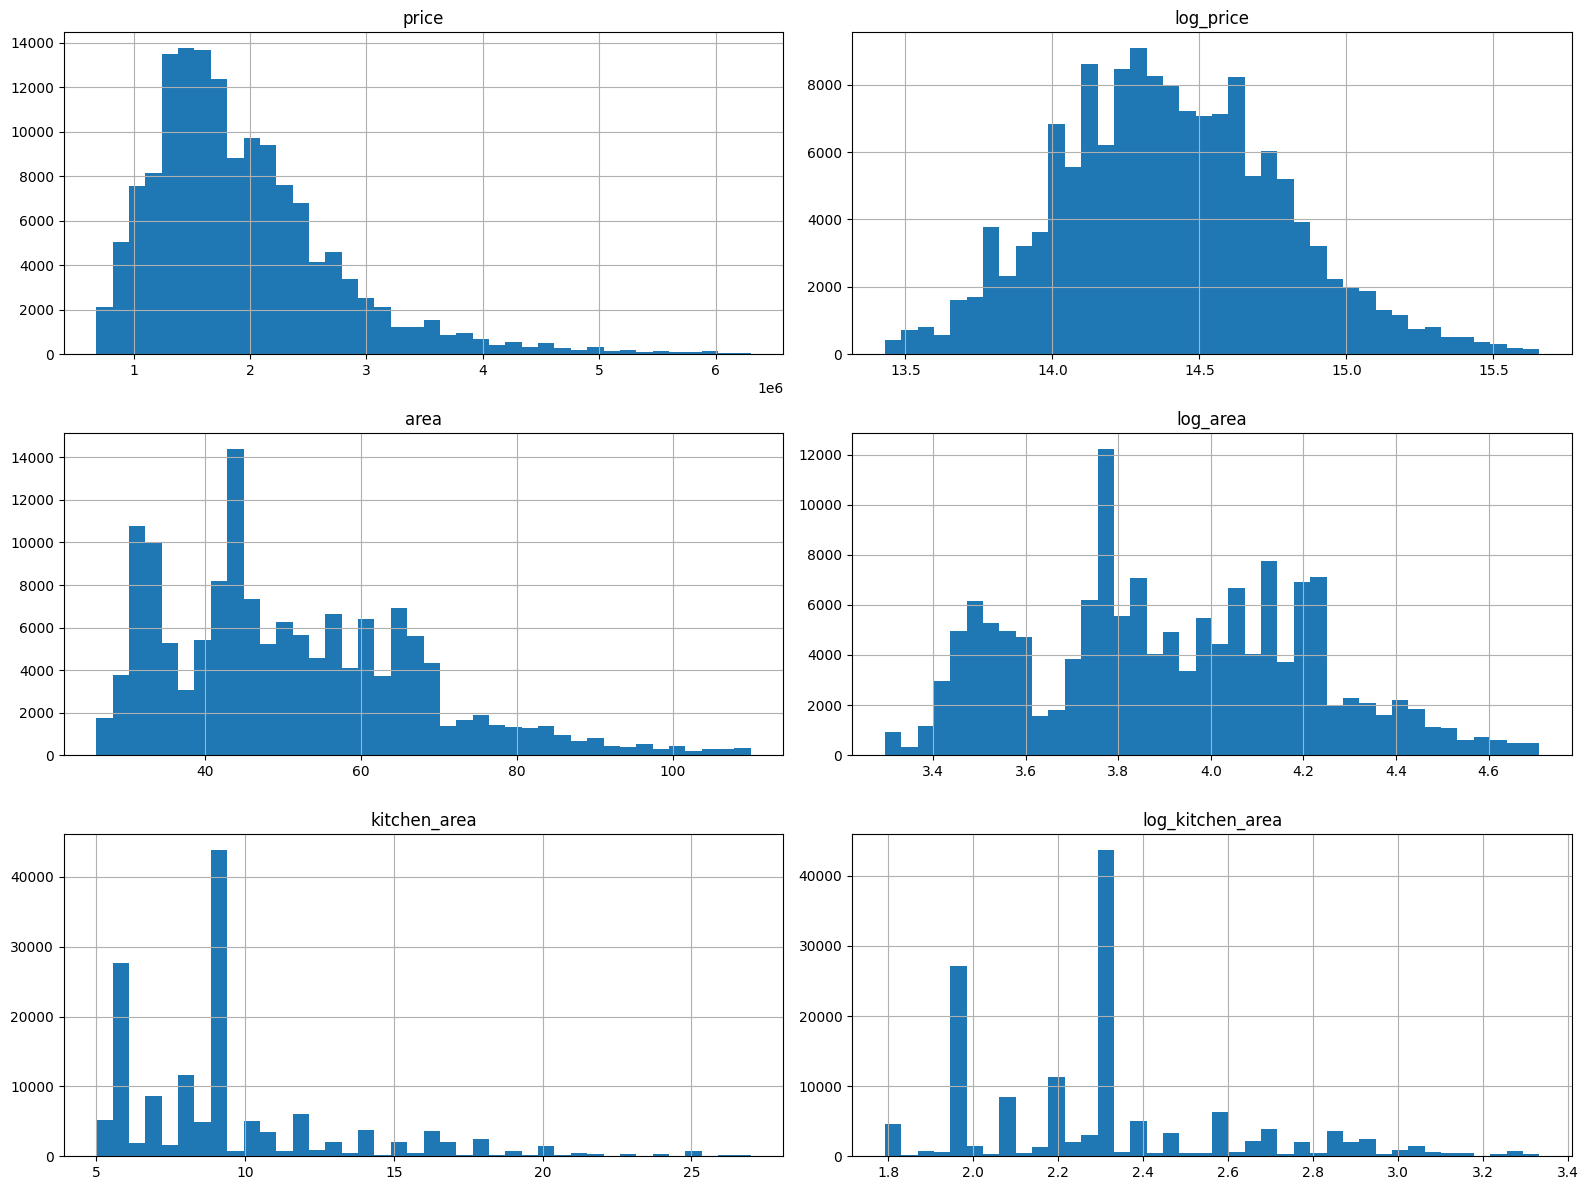

In [55]:
from matplotlib import pyplot as plt


f = ['price', 'log_price', 'area', 'log_area', 'kitchen_area', 'log_kitchen_area']

df[f].hist(bins=40, figsize=(16, 12))

plt.tight_layout()
plt.show()

### Проверка на нормальность распределения таргета

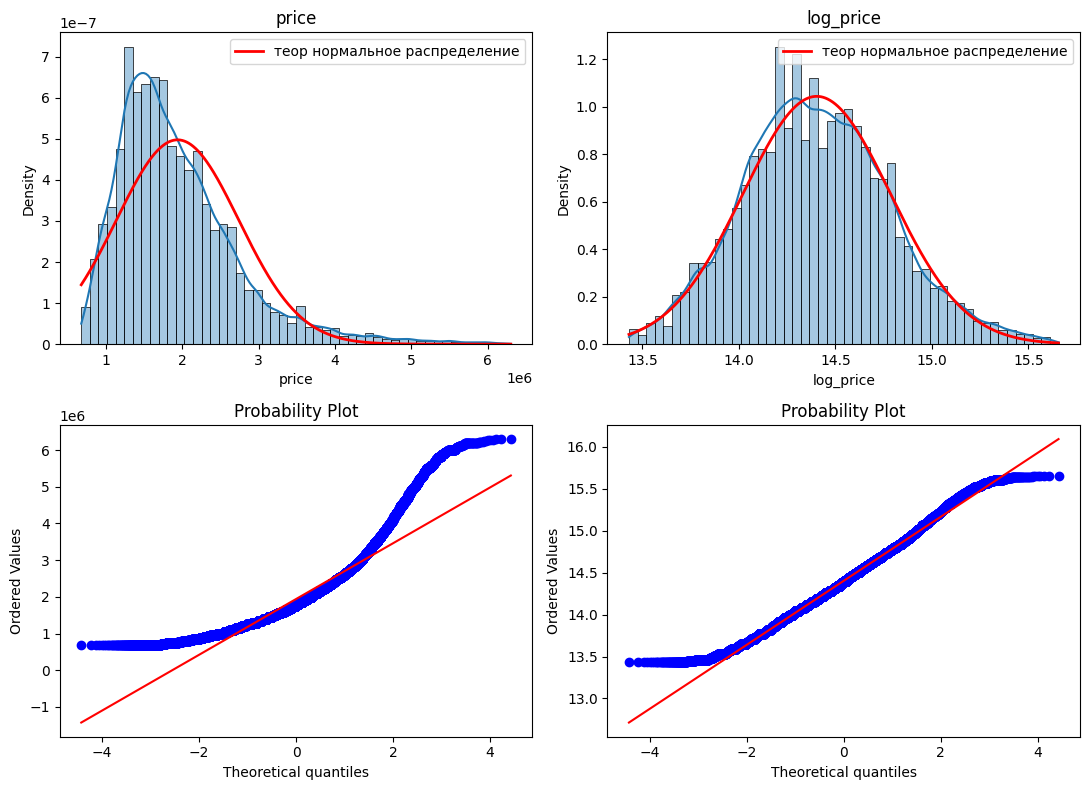

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 145273.
  res = hypotest_fun_out(*samples, **kwds)


,column,normaltest_pvalue,shapiro_pvalue
0,price,0.0,0.0
1,log_price,0.0,0.0


In [56]:
from scipy import stats

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for i, c in enumerate(['price', 'log_price']):
    data = df[c].dropna()

    sns.histplot(data, bins=50, stat='density',
                 kde=True, ax=ax[0, i], alpha=0.4)

    x = np.linspace(data.min(), data.max(), 1000)
    y = stats.norm.pdf(x, data.mean(), data.std())

    ax[0, i].plot(x, y, color='red', lw=2,
                  label='теор нормальное распределение')
    ax[0, i].set_title(c)
    ax[0, i].legend()


    stats.probplot(df[c], dist='norm', plot=ax[1, i])
plt.tight_layout()
plt.show()


normality = pd.DataFrame([
    {
        'column': c,
        'normaltest_pvalue': stats.normaltest(df[c].dropna()).pvalue.round(5),
        'shapiro_pvalue': stats.shapiro(df[c].dropna()).pvalue.round(5)
    } for c in ['price', 'log_price']
])
display(normality)

Из графиков видно, что распределение логарифмированного таргета достаточно близко к нормальному, несмотря на то, что по критериям нормальности p-value стремится к нулю из-за большого размера выборки
Исходное распределение нормальным не является в силу правосторонней асимметрии

### Проверка признаков на мультиколлинеарность

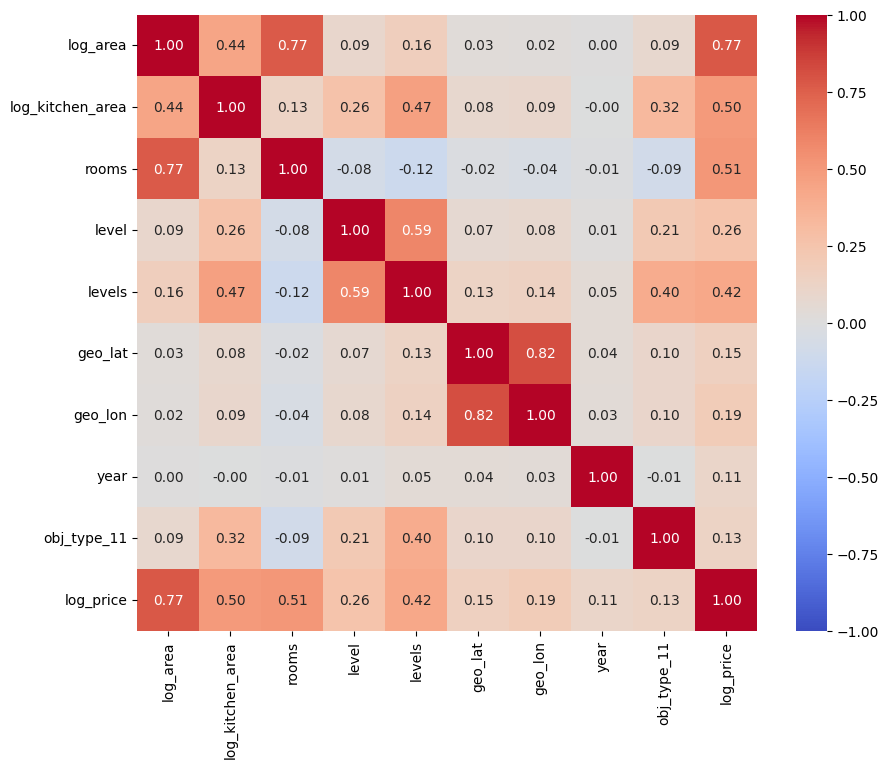

,feature,VIF
0,log_area,3.65
1,rooms,3.12
2,geo_lon,3.00
3,geo_lat,2.99
4,levels,2.08
5,log_kitchen_area,1.69
6,level,1.54
7,obj_type_11,1.24
8,year,1.01


In [57]:
from sklearn.linear_model import LinearRegression

features = ['log_area', 'log_kitchen_area', 'rooms', 'level', 'levels',
            'geo_lat', 'geo_lon', 'year', 'obj_type_11', 'building_type']

cat_features = ['building_type']
num_features = [f for f in features if f not in cat_features]

corr = df[num_features + ['log_price']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)
plt.show()
vif = {}
for f in num_features:
    rest = df[num_features].drop(columns=f)
    vif[f] = 1 / (1 - LinearRegression().fit(rest, df[f]).score(rest, df[f]))

vif_df = (
    pd.DataFrame({
        'feature': list(vif.keys()),
        'VIF': list(vif.values())
    })
    .sort_values('VIF', ascending=False)
    .round(2)
    .reset_index(drop=True)
)
vif_df

Значения в матрице корреляции признаков не превышают 0.81, а значения VIF по признаков < 5, следовательно, нет оснований исключать признаки на основе мультиколлинеарности

## Задача 2

### Разбиение на трейн и тест

In [58]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.svm import LinearSVR

SEED=179562398
LOG_TARGET = True

X = df[features]
y = df['log_price'] if LOG_TARGET else df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED
)


In [59]:
from sklearn.metrics import mean_squared_error


def to_orig(y):
    return np.expm1(y) if LOG_TARGET else y

def rmse_orig(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(to_orig(y_true), to_orig(y_pred))))

def rmse_target(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

### Пайплайн для моделей

Для численных признаков используем StandardScaler, для building_type OneHotEncoder

In [60]:
def make_pipeline(model):
    transformer = ColumnTransformer([
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features),
    ]).set_output(transform='pandas')
    return Pipeline([
        ('transformer', transformer),
        ('model', model),
    ])

### Обучение моделей

In [61]:
dummy = make_pipeline(DummyRegressor()).fit(X_train, y_train)

In [62]:
ridge = make_pipeline(Ridge()).fit(X_train, y_train)

In [63]:
svr = make_pipeline(SVR(kernel='linear', cache_size=1000)).fit(X_train, y_train)

### Инференс и сравнение метрик по RMSE

In [64]:
pred_dummy = dummy.predict(X_test)
pred_ridge = ridge.predict(X_test)
pred_svr = svr.predict(X_test)

res = pd.DataFrame(
    {
        'RMSE': [
            rmse_orig(y_test, pred_dummy),
            rmse_orig(y_test, pred_ridge),
            rmse_orig(y_test, pred_svr),
        ],
        'RMSE (log)': [
            rmse_target(y_test, pred_dummy),
            rmse_target(y_test, pred_ridge),
            rmse_target(y_test, pred_svr),
        ],
    },
    index=['Dummy', 'Ridge', 'SVR'],
).round(3)
res

,RMSE,RMSE (log)
Dummy,814225.629,0.382
Ridge,420959.861,0.201
SVR,420648.057,0.201
